# Semantic Search Engine

Two complementary explorations of embedding-based search, as an alternative to keyword matching:

1. **Text-to-text semantic search** — documents are embedded with a pre-trained sentence-transformer model and indexed with [Annoy](https://github.com/spotify/annoy) (Approximate Nearest Neighbors Oh Yeah) for fast similarity search.
2. **Text-to-image search** — a query like *"a dog running on the grass"* is used to search a database of photos directly, using [CLIP](https://openai.com/research/clip) and [BLIP](https://github.com/salesforce/BLIP), two vision-language models compared head-to-head on the same queries.

## Setup

In [ ]:
# Install dependencies
%pip install -q sentence-transformers annoy transformers torch torchvision matplotlib pillow kaggle pandas numpy

In [ ]:
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

In [ ]:
# Download the Flickr8k image dataset (used for text-to-image search below)
# Requires a Kaggle account + API token (~/.kaggle/kaggle.json) -- see data/README.md
!mkdir -p ../data
!kaggle datasets download -d adityajn105/flickr8k -p ../data
!unzip -q ../data/flickr8k.zip -d ../data/flickr8k/

## Text-to-Text Semantic Search (Sentence Embeddings + Annoy)

**How it works:** a sentence-transformer model maps each text document to a dense low-dimensional vector. Instead of representing documents with words as independent dimensions (where different terms have no inherent similarity, so "car" ≠ "automobile"), the network learns each word's representation from the words that typically surround it in context. As a result, words and documents that appear in similar contexts end up close together in the same embedding space — so "car engine repair" and "automobile mechanic" get similar embeddings even with no exact word overlap. This means the embeddings capture semantic meaning rather than just keyword matching.

In [4]:
# Generate vector embeddings for a set of text documents using a pre-trained sentence-transformer model
from sentence_transformers import SentenceTransformer

embed_model = SentenceTransformer('all-MiniLM-L6-v2')

def generate_embeddings(documents):
    return embed_model.encode(list(documents), show_progress_bar=True)

In [ ]:
# Load the text corpus used for semantic search and generate embeddings
from pathlib import Path
import pandas as pd

csv_file = Path("../data/food_recipes.csv")
if not csv_file.exists():
    raise FileNotFoundError(
        "food_recipes.csv not found -- see data/README.md for where to get it."
    )

df = pd.read_csv(csv_file)
doc_embeddings = generate_embeddings(df["directions"])
doc_embeddings.shape

(50000, 384)

**Why Annoy:** Annoy builds large, read-only, file-based index structures that are memory-mapped, so many processes can share the same index with a small memory footprint. To index, we add each document's embedding vector to an `AnnoyIndex` of the right dimensionality, build it with a chosen number of trees, and save it to disk. To query, we load the saved index and ask it for the nearest neighbours of a query vector.

In [6]:
# Build an Annoy index from the generated embeddings
from annoy import AnnoyIndex

def build_annoy_index(embeddings, n_trees=10, path='text.ann'):
    f = embeddings.shape[1]
    t = AnnoyIndex(f, 'angular')
    for i in range(embeddings.shape[0]):
        v = embeddings[i]
        t.add_item(i, v)
    t.build(n_trees)
    t.save(path)
    return f

In [7]:
f = build_annoy_index(doc_embeddings, n_trees=10, path='text.ann')

**How search works:** first, load the saved index with the same dimensionality and metric it was built with. Encode the query text with the *same* pre-trained model, so it lands in the same embedding space as the documents. Then pass the query vector to the index and ask for the desired number of nearest neighbours — Annoy returns the indices of the closest document vectors by embedding similarity. Finally, map those indices back to the original documents to display the results. This finds the most similar documents by embedding similarity rather than by exact keyword overlap.

In [8]:
# Load the index and perform a semantic search over it
u = AnnoyIndex(f, 'angular')
u.load('text.ann')

def semantic_search(query_text, results):
    query_vector = embed_model.encode([query_text])[0]
    nn_indices = u.get_nns_by_vector(query_vector, results)
    for idx in nn_indices:
        print(f"Title: {df.iloc[idx]['title']}, Directions: {df.iloc[idx]['directions']}")

# example query
semantic_search("how to bake cookies", 3)

Title: Sugar Cookies, Directions: Combine eggs, butter, oil, and sugar., Mix together, then add the flour mixture., Roll into small balls and place on ungreased cookie sheet., Flatten cookies with a glass bottom dipped in sugar. Bake at 350 degrees for 8-10 minutes (or until lightly browned). Makes 6 dozen cookies.
Title: Spritz Cookies, Directions: Heat oven to 400°., In large bowl, cream the powdered sugar, butter, vanilla and egg until light and fluffy., Stir in flour and salt; blend well., Fill cookie press; press dough into desired shapes onto ungreased cookie sheets., Bake for 5 to 7 minutes, or until lightly browned on edges., Immediately remove from cookie sheets., Makes approximately 5 dozen cookies.
Title: Monster Cookies, Directions: Mix all ingredients together., Place on greased cookie sheet and flatten slightly., Cookies should be about 5-inches in diameter., Bake at 350° for 12 minutes., Makes a huge amount.


### Advantages and limitations of Annoy for semantic search

**Advantages:** since both queries and documents are mapped to the same embedding space, similarity is based on semantic meaning, not exact word overlap, so a query for "car repair" can match "automobile mechanic" even though car ≠ automobile. This handles synonyms and contextual similarity that traditional keyword search misses. Annoy itself is fast and memory-efficient: it builds small, read-only, memory-mapped file structures and uses approximate nearest-neighbour search, so it scales well to large collections.

**Limitations:** Annoy is approximate, so it may not always return the exact nearest neighbours (precision depends on the number of trees — more trees means more memory and slower build time). Result quality depends entirely on the pre-trained embedding model, and embeddings can conflate subtly related items. The index is read-only, so adding new documents means rebuilding it. Keyword search, by contrast, is exact and interpretable, and is better when the user wants precise term matches.

## Text-to-Image Search: CLIP vs. BLIP

Two vision-language models well suited to searching images with a text query:

1. **ALIGN** (Google) — like CLIP, it learns a joint image-text embedding space using contrastive learning, but is trained on a much larger, noisier set of image-and-text pairs, so it handles ambiguous text, typos, and colloquial descriptions better.
2. **BLIP** (Bootstrapping Language-Image Pre-training) — a vision-language model that also produces aligned image and text embeddings for image-text retrieval, and additionally cleans noisy web captions during pre-training to improve alignment quality. This is the one implemented and compared against CLIP below.

In [9]:
import torch
import numpy as np
import os
from PIL import Image
import matplotlib.pyplot as plt
from transformers import CLIPProcessor, CLIPModel, BlipProcessor, BlipForImageTextRetrieval

device = "cuda" if torch.cuda.is_available() else "cpu"

# define the image paths
image_path = os.listdir('../data/flickr8k/Images/')
image_path = ['../data/flickr8k/Images/' + path for path in image_path if '.jpg' in path]
image_path.sort()
image_path = image_path[:200]   # use a subset to keep it fast

CLIP results for 'a dog running on the grass'
./flickr8k/Images/1019077836_6fc9b15408.jpg 0.321


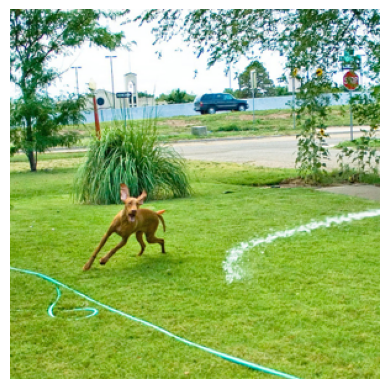

./flickr8k/Images/1164131282_b30926f332.jpg 0.308


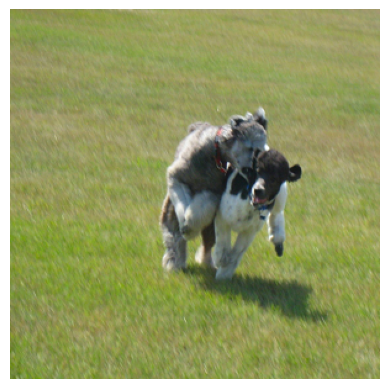

./flickr8k/Images/1009434119_febe49276a.jpg 0.307


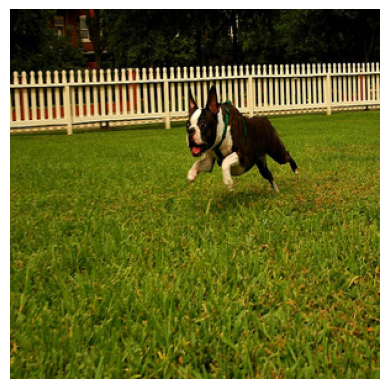

./flickr8k/Images/1119418776_58e4b93eac.jpg 0.305


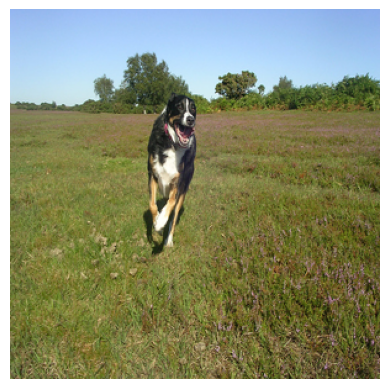

BLIP results for 'a dog running on the grass'
./flickr8k/Images/1009434119_febe49276a.jpg 0.545


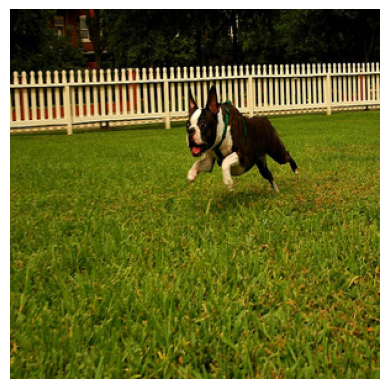

./flickr8k/Images/1119418776_58e4b93eac.jpg 0.504


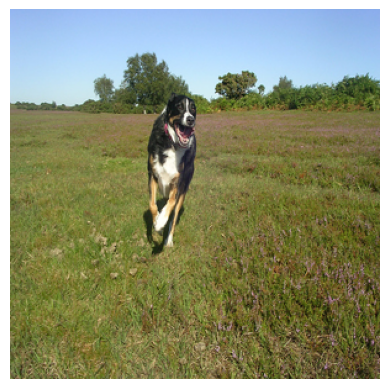

./flickr8k/Images/1019604187_d087bf9a5f.jpg 0.476


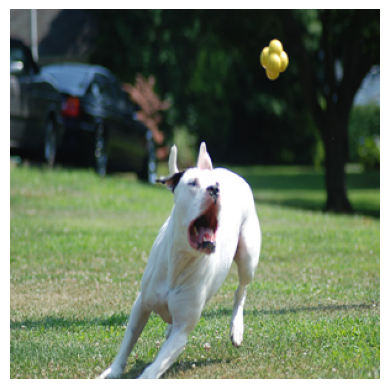

./flickr8k/Images/1119015538_e8e796281e.jpg 0.468


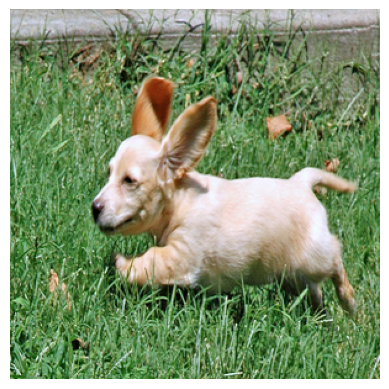

In [10]:
# Compare an alternative model (BLIP) against CLIP on the same text search task
# CLIP
clip_model = CLIPModel.from_pretrained("openai/clip-vit-base-patch32").to(device)
clip_proc = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")

def clip_image_embeds(paths):
    embs = []
    for p in paths:
        img = Image.open(p).convert("RGB")
        inputs = clip_proc(images=img, return_tensors="pt").to(device)
        with torch.no_grad():
            vision_outputs = clip_model.vision_model(
                pixel_values=inputs["pixel_values"]
            )
            pooled = vision_outputs.pooler_output
            e = clip_model.visual_projection(pooled)
        embs.append(e.cpu().numpy()[0])
    return np.array(embs)

def clip_text_embed(text):
    inputs = clip_proc(text=[text], return_tensors="pt", padding=True).to(device)
    with torch.no_grad():
        text_outputs = clip_model.text_model(
            input_ids=inputs["input_ids"],
            attention_mask=inputs["attention_mask"]
        )
        pooled = text_outputs.pooler_output
        e = clip_model.text_projection(pooled)
    return e.cpu().numpy()[0]

# BLIP
blip_model = BlipForImageTextRetrieval.from_pretrained("Salesforce/blip-itm-base-coco").to(device)
blip_proc = BlipProcessor.from_pretrained("Salesforce/blip-itm-base-coco")

def blip_image_embeds(paths):
    embs = []
    for p in paths:
        img = Image.open(p).convert("RGB")
        inputs = blip_proc(images=img, return_tensors="pt").to(device)
        with torch.no_grad():
            vision_outputs = blip_model.vision_model(**inputs)
            pooled = vision_outputs.last_hidden_state[:, 0, :]
            e = blip_model.vision_proj(pooled)
        embs.append(e.cpu().numpy()[0])
    return np.array(embs)

def blip_text_embed(text):
    inputs = blip_proc(text=text, return_tensors="pt").to(device)
    with torch.no_grad():
        text_outputs = blip_model.text_encoder(
            input_ids=inputs["input_ids"],
            attention_mask=inputs["attention_mask"]
        )
        pooled = text_outputs.last_hidden_state[:, 0, :]
        e = blip_model.text_proj(pooled)
    return e.cpu().numpy()[0]

# precompute image embeddings for both models
clip_img = clip_image_embeds(image_path)
blip_img = blip_image_embeds(image_path)

def search_and_show(text, img_embeds, text_embed_fn, results=4, title=""):
    q = text_embed_fn(text)
    q = q/np.linalg.norm(q)
    db = img_embeds/np.linalg.norm(img_embeds, axis=1, keepdims=True)
    scores = db @ q
    top = np.argsort(-scores)[:results]
    print(f"{title} results for '{text}'")
    for idx in top:
        print(image_path[idx], round(float(scores[idx]), 3))
        plt.imshow(Image.open(image_path[idx]).resize((300, 300)))
        plt.axis('off'); plt.show()

query = "a dog running on the grass"
search_and_show(query, clip_img, clip_text_embed, 4, "CLIP")
search_and_show(query, blip_img, blip_text_embed, 4, "BLIP")

### Comparing the results

For the query "a dog running on the grass", both models returned relevant dog images, and several of the top results overlap between the two lists — which makes sense, since both map images and text into a shared embedding space and rank by cosine similarity.

The main difference is in the similarity scores: BLIP's top matches scored noticeably higher (around 0.55) and were more separated from each other, while CLIP's scores were lower and closer together (around 0.30–0.32), suggesting CLIP was less confident in distinguishing its top matches.

**Strengths and weaknesses:**
- CLIP is fast and lightweight, and because it was trained on 400 million image-text pairs it generalises well to everyday concepts, making it a strong, cheap baseline. Its weakness is that its scores are less separated, so it can be less confident on fine-grained distinctions.
- BLIP uses a stronger vision-language design with caption bootstrapping, giving higher and better-separated similarity scores and often capturing finer detail. Its weakness is that it's heavier and slower to run than CLIP, and needs more memory.

## Acknowledgements

- [Annoy](https://github.com/spotify/annoy)
- [Sentence-Transformers](https://www.sbert.net/)
- ALIGN: Jia et al., "Scaling Up Visual and Vision-Language Representation Learning With Noisy Text Supervision," ICML 2021, [arXiv:2102.05918](https://arxiv.org/abs/2102.05918)
- BLIP: Li et al., "BLIP: Bootstrapping Language-Image Pre-training for Unified Vision-Language Understanding and Generation," ICML 2022, [arXiv:2201.12086](https://arxiv.org/abs/2201.12086)